# Linear and Logistic Regression

Linear and logistic regression are two supervised learning techniques used in machine learning to estimate the value or class of a case study given a set of characteristics and statistical patterns analyzed in past case studies. Linear regression aims to estimate a certain numerical value given a set of variables (a regression algorithm). Logistic regression, on the other hand, focuses on classifying a given case study (a classification algorithm).

## II – Logistic Regression with Advertising Dataset
The aim of this exercise is to estimate whether a particular internet user has clicked on an advert using a logistic regression classification model. A dataset showing the habits of various internet users and illustrating a set of characteristics about each user and their decision-making is provided to develop this model. The dataset is available at https://bit.ly/3CMO63B.

After downloading the dataset, the intention is to:

## T1.
Load the dataset using the pandas.read_csv(…) function.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import metrics
import time

In [3]:
ds_initial = pd.read_csv('datasets/advertising.csv')

## T2.
Apply methods for data exploration and visualization.

In [4]:
ds_initial.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Daily Time Spent on Site  1000 non-null   float64
 1   Age                       1000 non-null   int64  
 2   Area Income               1000 non-null   float64
 3   Daily Internet Usage      1000 non-null   float64
 4   Ad Topic Line             1000 non-null   str    
 5   City                      1000 non-null   str    
 6   Male                      1000 non-null   int64  
 7   Country                   1000 non-null   str    
 8   Timestamp                 1000 non-null   str    
 9   Clicked on Ad             1000 non-null   int64  
dtypes: float64(3), int64(3), str(4)
memory usage: 78.3 KB


In [5]:
ds_initial.describe()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Clicked on Ad
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,65.000200,36.009000,55000.000080,180.000100,0.481000,0.50000
std,15.853615,8.785562,13414.634022,43.902339,0.499889,0.50025
min,32.600000,19.000000,13996.500000,104.780000,0.000000,0.00000
25%,51.360000,29.000000,47031.802500,138.830000,0.000000,0.00000
50%,68.215000,35.000000,57012.300000,183.130000,0.000000,0.50000
75%,78.547500,42.000000,65470.635000,218.792500,1.000000,1.00000
max,91.430000,61.000000,79484.800000,269.960000,1.000000,1.00000


In [8]:
print('Valores em falta:', ds_initial.isnull().sum().sum())
print(ds_initial['Clicked on Ad'].value_counts())

Valores em falta: 0
Clicked on Ad
0    500
1    500
Name: count, dtype: int64


<Axes: >

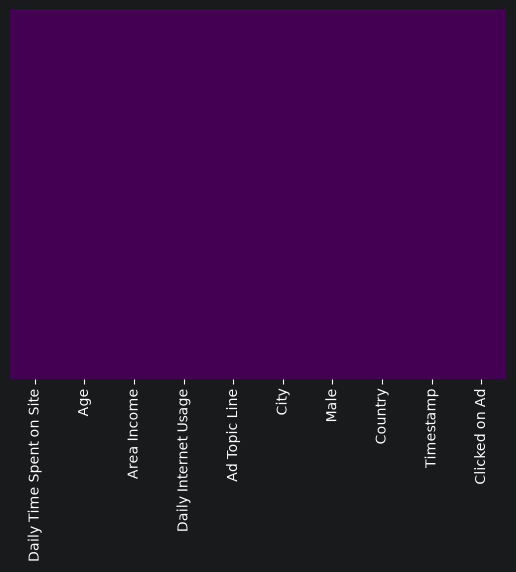

In [6]:
sns.heatmap(ds_initial.isnull(), yticklabels=False, cbar=False, cmap='viridis')

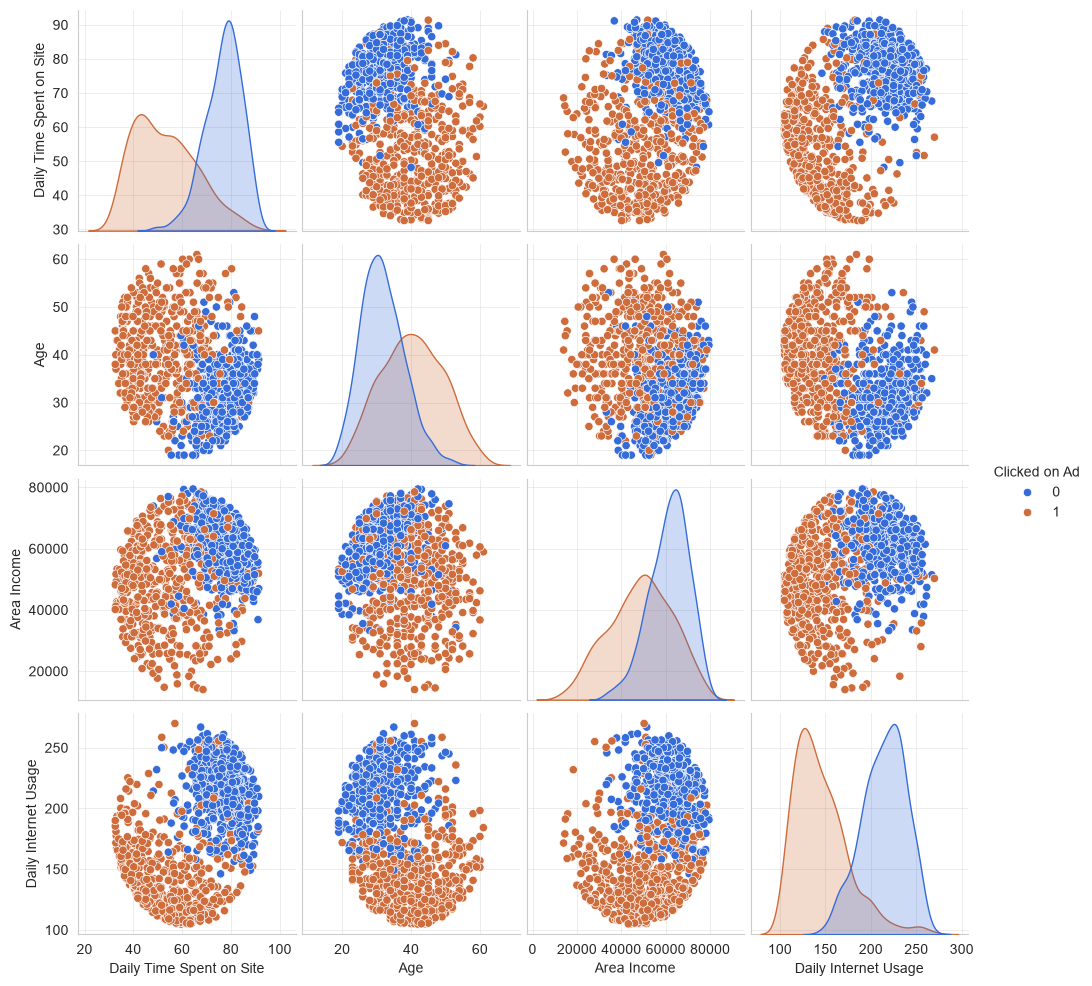

In [12]:
sns.pairplot(ds_initial[['Daily Time Spent on Site','Age','Area Income','Daily Internet Usage','Clicked on Ad']], hue='Clicked on Ad')
plt.show()

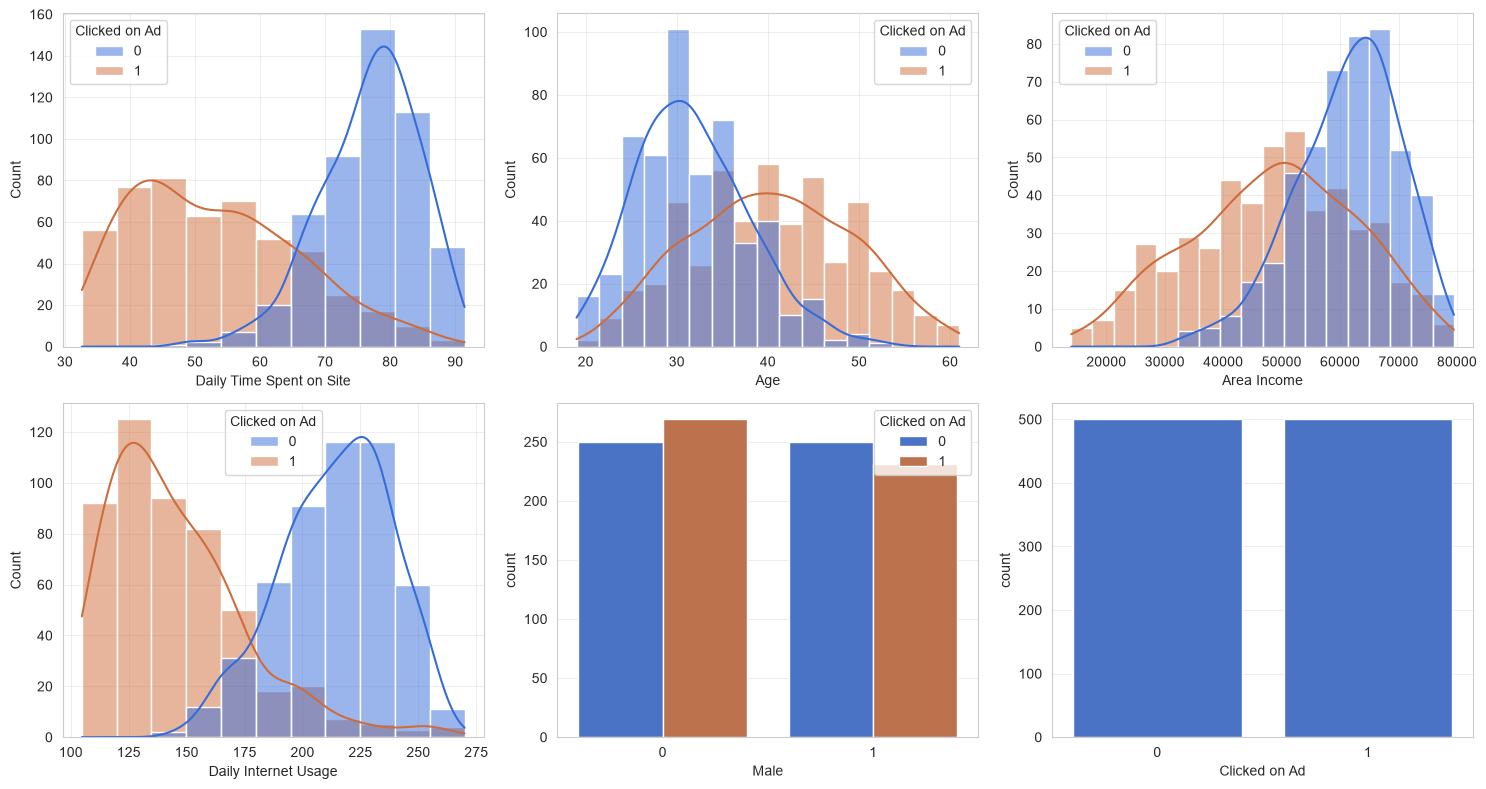

In [10]:
sns.set_style('whitegrid')
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ['Daily Time Spent on Site','Age','Area Income','Daily Internet Usage']):
    sns.histplot(data=ds_initial, x=col, hue='Clicked on Ad', kde=True, ax=ax)
sns.countplot(x='Male', hue='Clicked on Ad', data=ds_initial, ax=axes[1,1])
sns.countplot(x='Clicked on Ad', data=ds_initial, ax=axes[1,2])
plt.tight_layout(); plt.show()

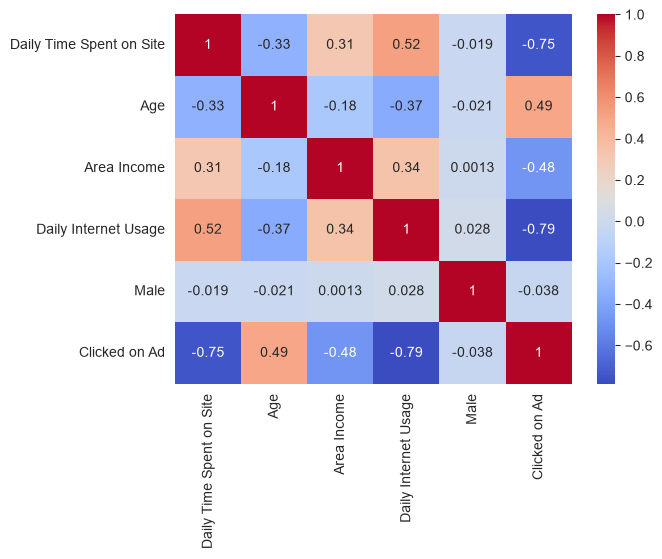

In [13]:
sns.heatmap(ds_initial.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

**Observações:**
- 1000 utilizadores, sem valores em falta e com classes **perfeitamente equilibradas** (500 clicaram, 500 não), pelo que a *accuracy* é uma métrica fiável.
- Correlação com `Clicked on Ad`: *Daily Internet Usage* -0.79, *Daily Time Spent on Site* -0.75, *Age* +0.49, *Area Income* -0.48 e *Male* ≈ -0.04 (irrelevante).
- Perfil de quem clica: passa **menos** tempo no site e na internet, é **mais velho** e vive em zonas com **menor rendimento**.
- As colunas `Ad Topic Line`, `City`, `Country` e `Timestamp` não são usadas (texto/alta cardinalidade; fora do enunciado).

## T3
Define the set of input and output variables of the model (i.e., input = [“Daily Time Spent on Site”, “Age”, “Area Income”, “Daily Internet Usage”, “Male”]; output = [“Clicked on Ad”]).

In [15]:
features = ['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage', 'Male']
X = ds_initial[features]
y = ds_initial['Clicked on Ad']

In [16]:
X

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male
0,68.95,35,61833.90,256.09,0
1,80.23,31,68441.85,193.77,1
2,69.47,26,59785.94,236.50,0
3,74.15,29,54806.18,245.89,1
4,68.37,35,73889.99,225.58,0
...,...,...,...,...,...
995,72.97,30,71384.57,208.58,1
996,51.30,45,67782.17,134.42,1
997,51.63,51,42415.72,120.37,1
998,55.55,19,41920.79,187.95,0


In [17]:
y

0      0
1      0
2      0
3      0
4      0
      ..
995    1
996    1
997    1
998    0
999    1
Name: Clicked on Ad, Length: 1000, dtype: int64

## T4
Prepare and organize the set of case studies from the dataset into training and test data using the sklearn.model_selection.train_test_split(…) function with test_size = 0.3.;

In [19]:
from sklearn.model_selection import train_test_split

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)
print(y_train.value_counts(), y_test.value_counts())

(700, 5) (300, 5) (700,) (300,)
Clicked on Ad
1    357
0    343
Name: count, dtype: int64 Clicked on Ad
0    157
1    143
Name: count, dtype: int64


## T5
Train various logistic regression models ( sklearn.linear_model.LogisticRegression) using the training data. Train with three different classifiers ( solver=...).


In [24]:
from sklearn.linear_model import LogisticRegression

In [25]:
solvers = ['newton-cg', 'lbfgs', 'liblinear']
models, preds = {}, {}

for s in solvers:
    start = time.process_time()
    m = LogisticRegression(solver=s, random_state=2022, max_iter=1000)
    m.fit(X_train, y_train)
    elapsed = time.process_time() - start
    models[s], preds[s] = m, m.predict(X_test)
    print(f"{s:10s} | tempo: {elapsed:.4f}s | iterações: {m.n_iter_[0]} | accuracy treino: {m.score(X_train, y_train):.4f} | teste: {m.score(X_test, y_test):.4f}")

newton-cg  | tempo: 0.0938s | iterações: 99 | accuracy treino: 0.9700 | teste: 0.9767
lbfgs      | tempo: 0.0469s | iterações: 128 | accuracy treino: 0.9700 | teste: 0.9767
liblinear  | tempo: 0.0000s | iterações: 17 | accuracy treino: 0.8929 | teste: 0.9233


C:\Users\filbr\PycharmProjects\DAA_26_27\.venv\Lib\site-packages\scipy\optimize\_linesearch.py:326: LineSearchWarning: The line search algorithm did not converge
  alpha_star, phi_star, old_fval, derphi_star = scalar_search_wolfe2(
C:\Users\filbr\PycharmProjects\DAA_26_27\.venv\Lib\site-packages\sklearn\utils\optimize.py:160: LineSearchWarning: The line search algorithm did not converge
  ret = line_search_wolfe2(


## T6.
Evaluate the classification performance of the models by creating confusion matrices ( sklearn.metrics.confusion_matrix(…)) and classification reports ( sklearn.metrics.classification_report(…)).

In [26]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

===== solver = 'newton-cg' =====
              precision    recall  f1-score   support

           0      0.969     0.987     0.978       157
           1      0.986     0.965     0.975       143

    accuracy                          0.977       300
   macro avg      0.977     0.976     0.977       300
weighted avg      0.977     0.977     0.977       300

===== solver = 'lbfgs' =====
              precision    recall  f1-score   support

           0      0.969     0.987     0.978       157
           1      0.986     0.965     0.975       143

    accuracy                          0.977       300
   macro avg      0.977     0.976     0.977       300
weighted avg      0.977     0.977     0.977       300

===== solver = 'liblinear' =====
              precision    recall  f1-score   support

           0      0.909     0.949     0.928       157
           1      0.941     0.895     0.918       143

    accuracy                          0.923       300
   macro avg      0.925     0.922

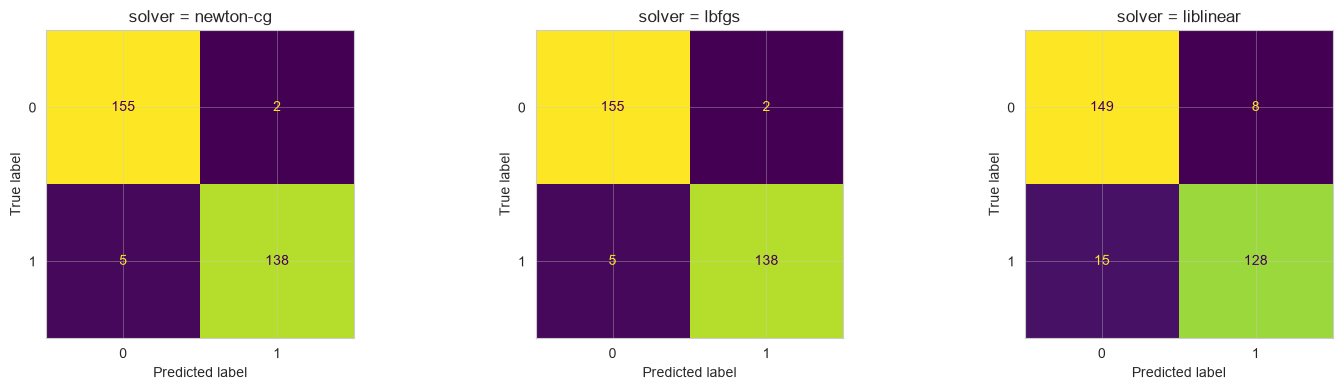

newton-cg  TN=155 FP=2 FN=5 TP=138
lbfgs      TN=155 FP=2 FN=5 TP=138
liblinear  TN=149 FP=8 FN=15 TP=128


In [27]:
for s in solvers:
    print(f"===== solver = '{s}' =====")
    print(classification_report(y_test, preds[s], digits=3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, s in zip(axes, solvers):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[s], ax=ax, colorbar=False)
    ax.set_title(f"solver = {s}")
plt.tight_layout(); plt.show()

for s in solvers:
    tn, fp, fn, tp = confusion_matrix(y_test, preds[s]).ravel()
    print(f"{s:10s} TN={tn} FP={fp} FN={fn} TP={tp}")

## T7
Given the results observed in T6, what conclusions can be drawn? In which situations does the model succeed or fail? How can the proposed learning model be improved? Which model (set of parameters) is the best?

## T7. Conclusões e análise crítica

**Resultados no teste (300 utilizadores):**

| Solver | Accuracy | TN | FP | FN | TP | F1 (classe 1) |
|---|---|---|---|---|---|---|
| newton-cg | 0.977 | 155 | 2 | 5 | 138 | 0.975 |
| lbfgs | 0.977 | 155 | 2 | 5 | 138 | 0.975 |
| liblinear | 0.923 | 149 | 8 | 15 | 128 | 0.918 |

**Conclusões:**
- `newton-cg` e `lbfgs` dão resultados **idênticos** (97.7%): só 7 erros em 300. Ambos têm precision 0.97–0.99 e recall 0.97–0.99 nas duas classes.
- `liblinear` é pior (92.3%, 23 erros). Os dados não estão normalizados (*Area Income* ~55 000 vs *Male* 0/1), o que prejudica os solvers e o `liblinear` sofre mais (acaba por não ajustar bem os coeficientes). Todos regularizam com L2 por defeito, e a regularização é sensível à escala das variáveis.
- **Onde o modelo acerta:** perfis claros (muito tempo na internet/site e jovem → não clica; pouco tempo e mais velho → clica).
- **Onde falha:** utilizadores com perfil intermédio/ambíguo. Nos melhores modelos há 5 falsos negativos (clicaram mas previu-se que não) e 2 falsos positivos. A recall da classe 1 (0.965) é ligeiramente inferior à da classe 0 (0.987).
- Como as classes estão equilibradas, a accuracy e o F1 contam a mesma história.

**Como melhorar:** (1) **normalizar** as variáveis (célula abaixo), (2) afinar o hiperparâmetro `C` (regularização) com `GridSearchCV`, (3) usar validação cruzada em vez de um único split, (4) remover `Male` (sem poder preditivo), (5) explorar variáveis de `Timestamp` (hora/dia) ou outros modelos (árvores, ensembles, como nas aulas 4 e 5).

**Melhor modelo:** `newton-cg` ou `lbfgs` (empatam em desempenho). Entre os dois, o `lbfgs` é o solver por defeito e escala melhor para datasets maiores, pelo que seria a escolha preferida. O `liblinear` não deve ser escolhido sem normalização.

In [28]:
### Extensão: o efeito da normalização (StandardScaler)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

rows = []
for s in ['newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga']:
    for scaled in [False, True]:
        clf = LogisticRegression(solver=s, random_state=2022, max_iter=1000)
        if scaled: clf = make_pipeline(StandardScaler(), clf)
        clf.fit(X_train, y_train)
        rows.append({'solver': s, 'normalizado': scaled, 'accuracy teste': round(clf.score(X_test, y_test), 4)})
pd.DataFrame(rows).pivot(index='solver', columns='normalizado', values='accuracy teste')

C:\Users\filbr\PycharmProjects\DAA_26_27\.venv\Lib\site-packages\scipy\optimize\_linesearch.py:326: LineSearchWarning: The line search algorithm did not converge
  alpha_star, phi_star, old_fval, derphi_star = scalar_search_wolfe2(
C:\Users\filbr\PycharmProjects\DAA_26_27\.venv\Lib\site-packages\sklearn\utils\optimize.py:160: LineSearchWarning: The line search algorithm did not converge
  ret = line_search_wolfe2(
C:\Users\filbr\PycharmProjects\DAA_26_27\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\filbr\PycharmProjects\DAA_26_27\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


normalizado,False,True
solver,,
lbfgs,0.9767,0.9767
liblinear,0.9233,0.9767
newton-cg,0.9767,0.9767
sag,0.5933,0.9767
saga,0.5233,0.9767


Com os dados normalizados, **todos os solvers** atingem 97.7%. Sem normalização, `sag` e `saga` falham quase por completo (59% e 52%: não convergem em escalas tão diferentes), e o `liblinear` cai para 92%. Isto confirma que a diferença entre solvers vem da escala das variáveis e não do algoritmo em si.

In [29]:
### Extensão: coeficientes (modelo normalizado) e afinação de C

best = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
pd.Series(best[-1].coef_[0], index=features, name='coeficiente (variáveis normalizadas)').sort_values()

Daily Time Spent on Site   -2.415855
Daily Internet Usage       -2.295303
Area Income                -1.392048
Male                       -0.223163
Age                         1.096859
Name: coeficiente (variáveis normalizadas), dtype: float64

Quanto maior o valor absoluto, maior o peso: *Daily Time Spent on Site* (-2.4) e *Daily Internet Usage* (-2.3) são as mais importantes (menos tempo → mais cliques), seguidas de *Area Income* (-1.4) e *Age* (+1.1). *Male* (-0.2) pesa muito pouco.

In [30]:
from sklearn.model_selection import GridSearchCV, cross_val_score
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
gs = GridSearchCV(pipe, {'logisticregression__C': [0.01, 0.1, 1, 10, 100]}, cv=5).fit(X_train, y_train)
print('Melhor C:', gs.best_params_, '| accuracy CV:', round(gs.best_score_, 4), '| accuracy teste:', round(gs.score(X_test, y_test), 4))
print('Validação cruzada 5-fold (dataset todo):', cross_val_score(pipe, X, y, cv=5).mean().round(4))

Melhor C: {'logisticregression__C': 1} | accuracy CV: 0.9671 | accuracy teste: 0.9767
Validação cruzada 5-fold (dataset todo): 0.971


A afinação de `C` não melhora o resultado (C = 1, o valor por defeito, já é o melhor) e a validação cruzada dá ~97% de accuracy, valor coerente com o do teste.